# 03 — InceptionV3 Transfer Öğrenmesi ile Sınıflandırma

Bu notebook, çalışmanın **dağıtılan sınıflandırıcısını** üretir:
`model_in_5_1.h5`. VGG16 varyantlarından (bkz. `02`) belirgin şekilde daha iyi
sonuç verdiği için üretim hattında ve masaüstü arayüzünde bu model kullanılır.

## Yaklaşım

1. ImageNet ağırlıklı InceptionV3 gövdesi yüklenir; **son 20 katman** ince ayar
   (fine-tuning) için çözülür, kalan katmanlar dondurulur.
2. Üzerine `GlobalAveragePooling2D → Dense(2048, relu) → Dropout(0.5) → Dense(2, softmax)`
   başlığı eklenir.
3. `val_loss` izlenerek en iyi model diskte tutulur, eğitim sonunda geri yüklenir.
4. Test kümesinde karışıklık matrisi ve sınıflandırma raporu üretilir.

Giriş boyutu **256×256**, toplam eğitim 50 epoch.


## 1. Ortam


In [ ]:
# Colab kullanıyorsanız:
# from google.colab import drive
# drive.mount("/content/drive")
# !unzip -q /content/drive/MyDrive/png.zip

import os
import shutil

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import layers, models
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ---------------------------------------------------------------- yollar
DATA_ROOT = "/content/drive/MyDrive/lungscan"
SPLIT_DIR = os.path.join(DATA_ROOT, "classification_3way")   # train/validation/test
MODELS_DIR = os.path.join(DATA_ROOT, "models")
BEST_MODEL_PATH = os.path.join(MODELS_DIR, "inceptionv3_best.h5")
PRODUCTION_PATH = os.path.join(MODELS_DIR, "model_in_5_1.h5")
for _d in (MODELS_DIR,):
    os.makedirs(_d, exist_ok=True)

# ------------------------------------------------------------- parametreler
INPUT_SIZE = (256, 256)
BATCH_SIZE = 64
EPOCHS = 50
VAL_RATIO = 0.15
TEST_RATIO = 0.15
SEED = 42


## 2. Üç yönlü veri kümesi (train / validation / test)

`04` numaralı notebook'tan farklı olarak burada eğitim sırasında erken durdurma ve
model seçimi için ayrı bir **doğrulama** kümesi tutulur; test kümesi yalnızca son
değerlendirmede kullanılır.


In [ ]:
def prepare_three_way_split(source_dir, split_dir, val_ratio=0.15, test_ratio=0.15, seed=42):
    """`normal/` ve `abnormal/` klasörlerini train/validation/test olarak kopyalar."""
    class_names = ("abnormal", "normal")

    for split in ("train", "validation", "test"):
        for name in class_names:
            os.makedirs(os.path.join(split_dir, split, name), exist_ok=True)

    for name in class_names:
        files = sorted(f for f in os.listdir(os.path.join(source_dir, name)) if f.endswith(".png"))

        train_files, rest = train_test_split(files, test_size=val_ratio + test_ratio,
                                            random_state=seed)
        val_files, test_files = train_test_split(
            rest, test_size=test_ratio / (val_ratio + test_ratio), random_state=seed
        )

        for split, items in (("train", train_files),
                             ("validation", val_files),
                             ("test", test_files)):
            for filename in items:
                shutil.copy(
                    os.path.join(source_dir, name, filename),
                    os.path.join(split_dir, split, name, filename),
                )
        print(f"{name:>8}: {len(train_files):>4} eğitim | {len(val_files):>4} doğrulama | "
              f"{len(test_files):>4} test")

    return split_dir


SOURCE_DIR = "/content/all"
prepare_three_way_split(
    SOURCE_DIR, SPLIT_DIR, val_ratio=VAL_RATIO, test_ratio=TEST_RATIO, seed=SEED
)


## 3. Veri üreteçleri


In [ ]:
train_datagen = ImageDataGenerator(rescale=1.0 / 255)
eval_datagen = ImageDataGenerator(rescale=1.0 / 255)


def make_generator(datagen, split, shuffle):
    return datagen.flow_from_directory(
        os.path.join(SPLIT_DIR, split),
        target_size=INPUT_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=shuffle,
    )


train_generator = make_generator(train_datagen, "train", True)
validation_generator = make_generator(eval_datagen, "validation", False)
test_generator = make_generator(eval_datagen, "test", False)

print("Sınıf indeksleri:", train_generator.class_indices)
print("Test kümesi:", test_generator.samples, "görüntü")


## 4. Model: InceptionV3 + ince ayar

Gövdenin yalnızca son 20 katmanı eğitilebilir; bu, ImageNet özniteliklerini korurken
modelin tıbbi görüntü dağılımına uyarlanmasını sağlar.


In [ ]:
def build_inceptionv3_classifier(input_size=(256, 256, 3), trainable_layers=20):
    """ImageNet ağırlıklı InceptionV3 üzerine sınıflandırma başlığı ekler.

    Args:
        trainable_layers: Gövdenin son kaç katmanının ince ayara açılacağı.
    """
    backbone = InceptionV3(input_shape=input_size, include_top=False, weights="imagenet")
    backbone.trainable = True
    for layer in backbone.layers[:-trainable_layers]:
        layer.trainable = False

    model = models.Sequential([
        backbone,
        layers.GlobalAveragePooling2D(),
        layers.Dense(2048, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(2, activation="softmax"),
    ])
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model


model = build_inceptionv3_classifier(INPUT_SIZE)
model.summary()


## 5. Eğitim


In [ ]:
callbacks = [
    ModelCheckpoint(BEST_MODEL_PATH, monitor="val_loss", save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
]

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks,
)

# Diskteki en iyi ağırlıkları geri yükle
if os.path.exists(BEST_MODEL_PATH):
    model.load_weights(BEST_MODEL_PATH)
print("Eğitim tamamlandı.")


In [ ]:
epochs = range(len(history.history["loss"]))

plt.figure()
plt.plot(epochs, history.history["loss"], label="eğitim kaybı")
plt.plot(epochs, history.history["val_loss"], label="doğrulama kaybı")
plt.xlabel("epoch")
plt.ylabel("kayıp")
plt.title("InceptionV3 — kayıp")
plt.legend()

plt.figure()
plt.plot(epochs, history.history["accuracy"], label="eğitim doğruluğu")
plt.plot(epochs, history.history["val_accuracy"], label="doğrulama doğruluğu")
plt.xlabel("epoch")
plt.ylabel("doğruluk")
plt.title("InceptionV3 — doğruluk")
plt.legend()
plt.show()


## 6. Test değerlendirmesi


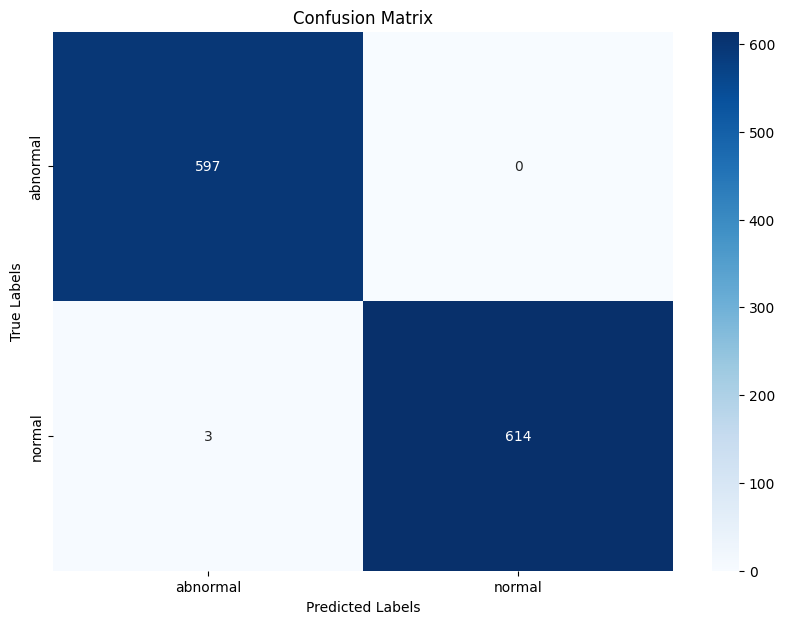

In [ ]:
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"Test kaybı: {test_loss:.4f} | Test doğruluğu: {test_accuracy:.4f}")

probabilities = model.predict(test_generator)
predicted_classes = np.argmax(probabilities, axis=1)
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

conf_matrix = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Tahmin edilen")
plt.ylabel("Gerçek")
plt.title("Karışıklık Matrisi")
plt.show()

print(classification_report(true_classes, predicted_classes, target_names=class_labels))


## 7. Üretim modeli

Eğitilen model, masaüstü arayüzünün (`app/lungscan_gui.py`) ve sürüm notlarında
paylaşılan `model_in_5_1.h5` dosyasının kaynağıdır.


In [ ]:
model.save(PRODUCTION_PATH)
print("Üretim modeli kaydedildi:", PRODUCTION_PATH)


## 8. Tahmin örnekleri

Test kümesinden rastgele örnekler; başlıkta gerçek etiket ve modelin güveni görünür.
Sınıf eşlemesi `ImageDataGenerator` tarafından alfabetik yapılır:
`abnormal → 0`, `normal → 1`.


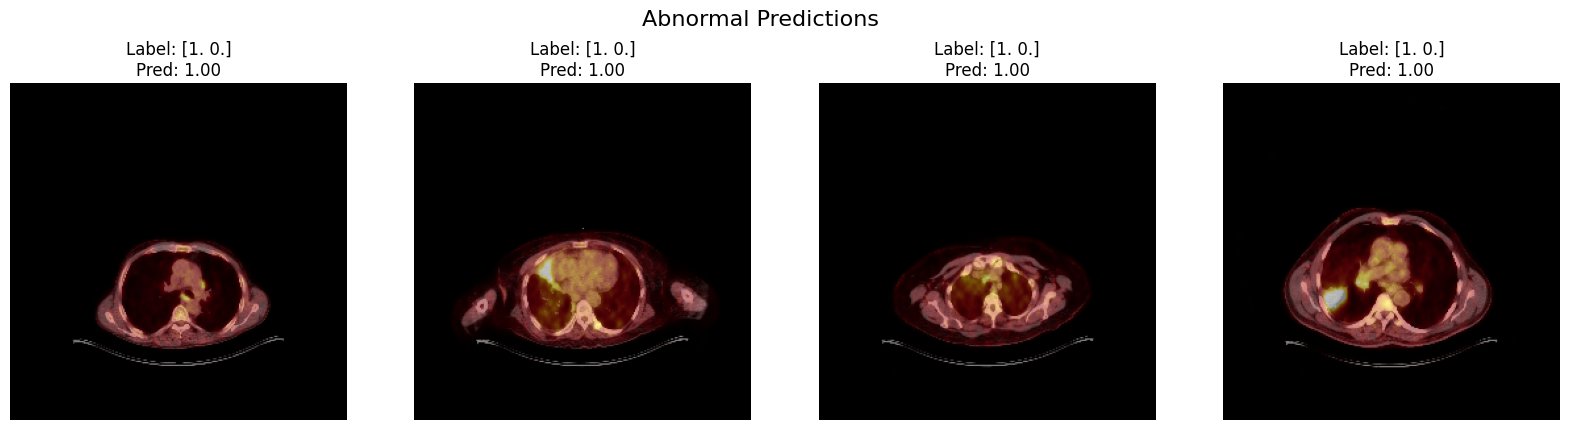

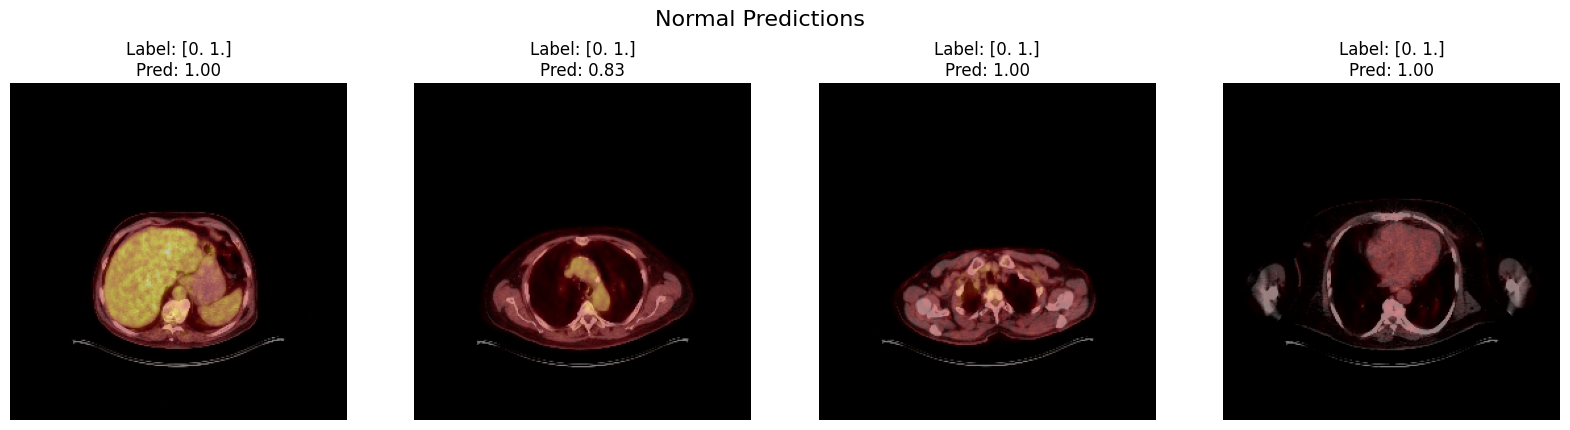

In [ ]:
def collect_predictions(generator, model, class_names=("abnormal", "normal")):
    """Üreteci tek geçişte tarar, sınıf adına göre gruplanmış tahminleri döndürür.

    Returns:
        {"abnormal": [(görüntü, gerçek_etiket, güven), ...], "normal": [...]}
    """
    grouped = {name: [] for name in class_names}
    generator.reset()

    for _ in range(len(generator)):
        images, labels = next(generator)
        predictions = model.predict(images, verbose=0)
        for i, probabilities in enumerate(predictions):
            predicted_index = int(np.argmax(probabilities))
            grouped[class_names[predicted_index]].append(
                (images[i], labels[i], float(probabilities[predicted_index]))
            )
    return grouped


prediction_groups = collect_predictions(test_generator, model)


def plot_predictions(title, samples, count=4):
    """Verilen örneklerden rastgele `count` tanesini yan yana gösterir."""
    if len(samples) < count:
        count = len(samples)
    if count == 0:
        print(f"{title}: örnek yok")
        return

    plt.figure(figsize=(20, 5))
    plt.suptitle(title, fontsize=16)
    for i, index in enumerate(np.random.choice(len(samples), count, replace=False), 1):
        image, label, confidence = samples[index]
        plt.subplot(1, count, i)
        plt.imshow(image)
        plt.title(f"Etiket: {np.argmax(label)}\nTahmin: {confidence:.2f}")
        plt.axis("off")
    plt.show()


plot_predictions("Anormal olarak tahmin edilenler", prediction_groups["abnormal"])
plot_predictions("Normal olarak tahmin edilenler", prediction_groups["normal"])


## Sonuçlar ve çıkarımlar

* InceptionV3 + ince ayar, VGG16 tabanlı varyantlara göre test kümesinde belirgin
  şekilde daha yüksek doğruluk verdi; dağıtımda bu model kullanıldı.
* Raporlanan test doğruluğu **%99,8**'dir (597+614 doğru / 1214 örnek; anormal
  sınıfında 0 hata, normal sınıfında 3 hata). Bu ölçüm, karışıklık matrisi
  notebook'un ilk sürümündeki çıktıdan alınmıştır.
* `GlobalAveragePooling2D` kullanımı, `Flatten`'e kıyasla parametre sayısını ciddi
  biçimde düşürür ve aşırı öğrenmeyi geciktirir.
* `Dropout(0.5)` ve yalnızca son 20 katmanın çözülmesi, küçük veri kümesinde
  kararlılığı artırır.

### Sınırlamalar

* Bölme **kesit düzeyindedir**; aynı hastanın kesitleri farklı kümelere düşebildiği
  için doğruluk iyimserdir (veri sızıntısı). Hasta düzeyinde bölme yapılmalıdır.
* Görüntüler zenginleştirilmiş (fused PET/BT) kesitlerdir; modelin kararı hangi
  sinyal kaynağına dayandığı ayrıştırılmamıştır. Klinik kullanım öncesi bu analiz
  (örn. sinyal ablasyonu) gereklidir.
* Bu bir retrospektif akademik çalışmadır; klinik tanı aracı değildir
  (bkz. `DISCLAIMER.md`).

> Görüntü işleme denemeleri (Otsu eşikleme, parlak bölge işaretleme, watershed)
> `denemeler/goruntu_isleme_denemeleri.ipynb` dosyasına taşınmıştır.
